# Лабораторная работа 2. Продвинутая инженерия признаков и отбор
**Вариант 1:** Titanic. Импутация: Simple (медиана), KNN, Iterative. Выбросы: IsolationForest. Отбор: Mutual Information + Lasso.
Модель на всех этапах — логистическая регрессия, метрика — ROC-AUC на 5-фолдовой CV по train.
Test откладываем сразу и трогаем только в финале.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # чтобы импортировать src/ из notebooks/
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (IterativeImputer экспериментальный)
from sklearn.feature_selection import SelectFromModel, SelectKBest, mutual_info_classif
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.data import NUM_COLS, RANDOM_STATE, RAW_PATH, load_xy
from src.transformers import OutlierRemover
from src.utils import build_pipeline, cv_auc, evaluate, grid_search, save_model

X, y = load_xy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
results = {}  # сводная таблица CV-метрик

## 1. Пропуски
Пропуски уже есть в данных (`age` ≈ 20%, `embarked` — 2 строки), искусственно их не создаём.
Тип пропусков в `age` — **MAR**: доля пропусков зависит от наблюдаемого признака `pclass` (у 3-го класса возраст часто не записан).

In [2]:
df = pd.read_csv(RAW_PATH)
df.groupby("pclass")["age"].apply(lambda s: s.isna().mean()).round(3)

pclass
1    0.139
2    0.060
3    0.277
Name: age, dtype: float64

## 2. Сравнение импутеров
Масштабирование стоит ДО импутера: KNN считает расстояния, а Iterative строит регрессии, поэтому оба чувствительны к масштабу.

In [3]:
imputers = {
    "Simple (median)": SimpleImputer(strategy="median"),
    "KNN (k=5)": KNNImputer(n_neighbors=5),
    "Iterative": IterativeImputer(random_state=RANDOM_STATE),
}
for name, imp in imputers.items():
    results[f"impute: {name}"] = cv_auc(build_pipeline(imp), X_train, y_train)
pd.DataFrame(results, index=["mean", "std"]).T.round(4)

,mean,std
impute: Simple (median),0.8532,0.0218
impute: KNN (k=5),0.8527,0.0239
impute: Iterative,0.8542,0.0217


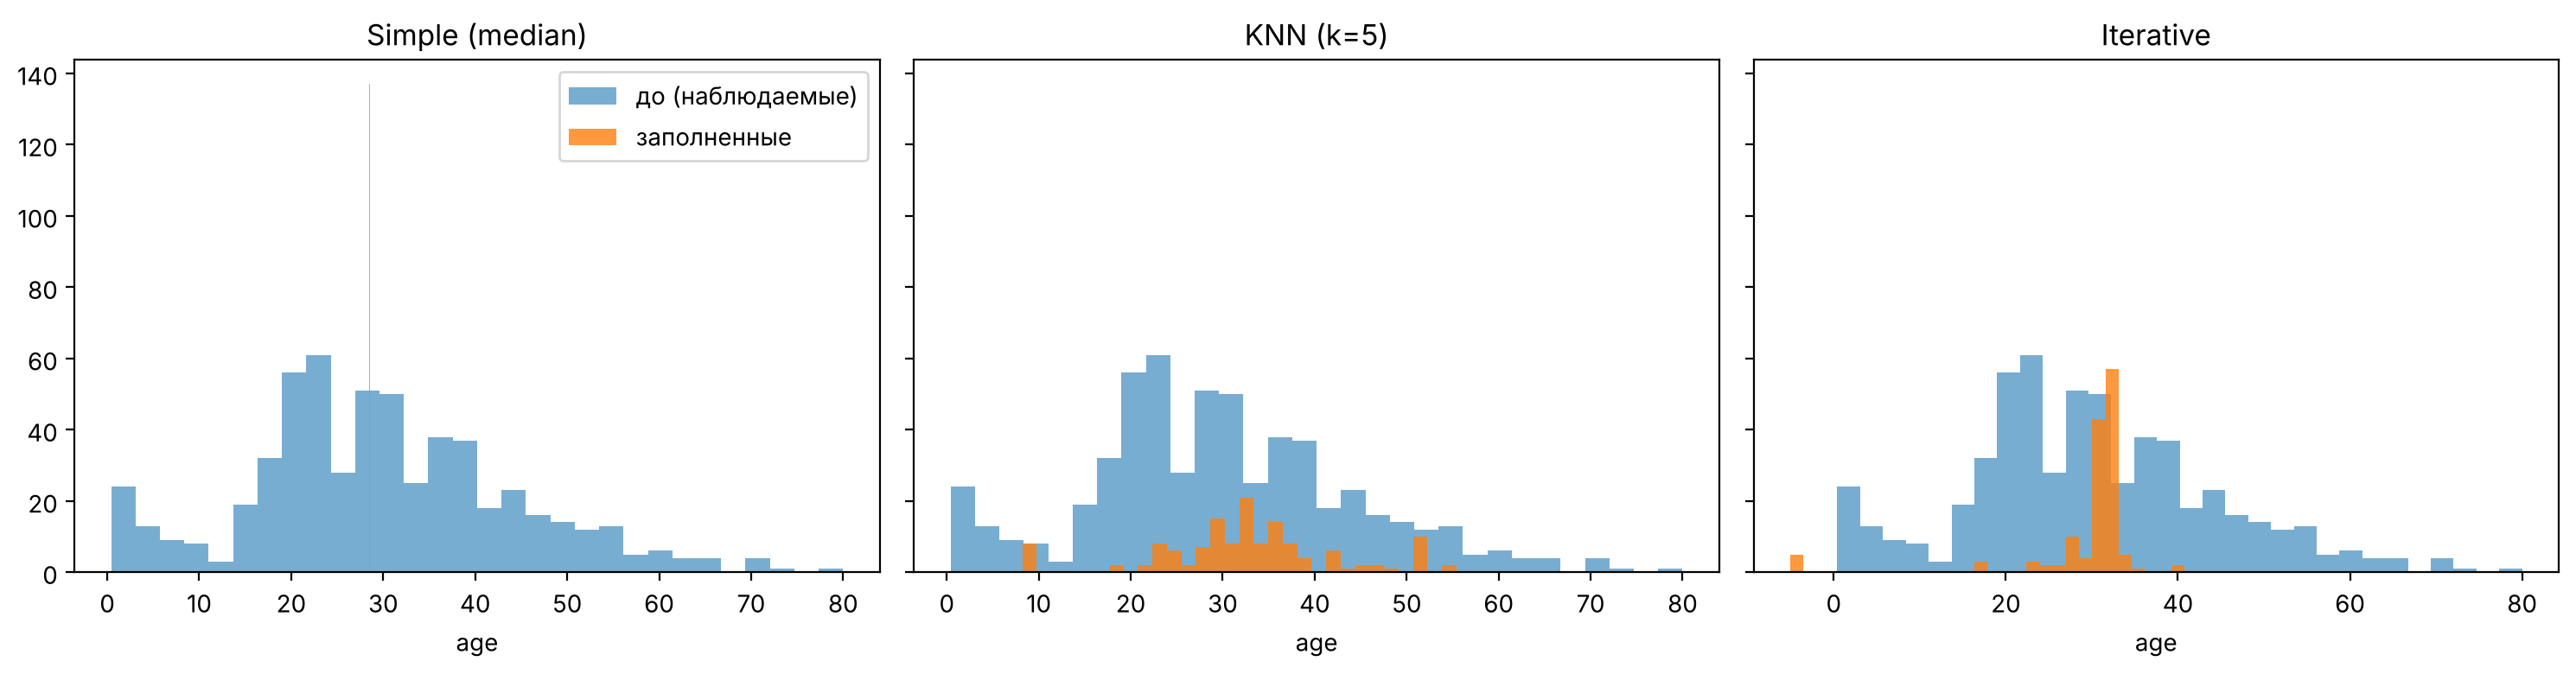

In [4]:
# распределение age: исходные значения vs значения, которыми заполнили пропуски
missing = X_train["age"].isna()
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, imp) in zip(axes, imputers.items()):
    scale_impute = make_pipeline(StandardScaler(), imp)
    filled = scale_impute.fit_transform(X_train[NUM_COLS])
    age = scale_impute[0].inverse_transform(filled)[:, NUM_COLS.index("age")]  # обратно в годы
    ax.hist(X_train["age"].dropna(), bins=30, alpha=0.6, label="до (наблюдаемые)")
    ax.hist(age[missing], bins=30, alpha=0.8, label="заполненные")
    ax.set_title(name); ax.set_xlabel("age")
axes[0].legend(); plt.tight_layout(); plt.show()

- **Медиана** ставит всем одно число: один пик, дисперсия занижается.
- **KNN** берёт среднее по 5 похожим пассажирам, поэтому разброс близок к исходному.
- **Iterative** предсказывает age линейной регрессией (BayesianRidge) по остальным признакам. Значения получаются кучнее, а линейная модель может выдать даже невозможный отрицательный возраст.

По ROC-AUC разница между методами в пределах std: в этих данных возраст влияет на выживание слабее, чем пол и класс.
Для дальнейших шагов берём импутер с лучшим CV ROC-AUC.

In [5]:
best_imp_name = max(imputers, key=lambda n: results[f"impute: {n}"][0])
best_imputer = imputers[best_imp_name]
best_imp_name

'Iterative'

## 3. Выбросы: IsolationForest
IsolationForest случайно режет пространство признаков: аномальную точку удаётся отделить за меньшее число разрезов.
`contamination=0.05` — ожидаемая доля выбросов. Для визуализации проецируем данные после предобработки в 2D через PCA.

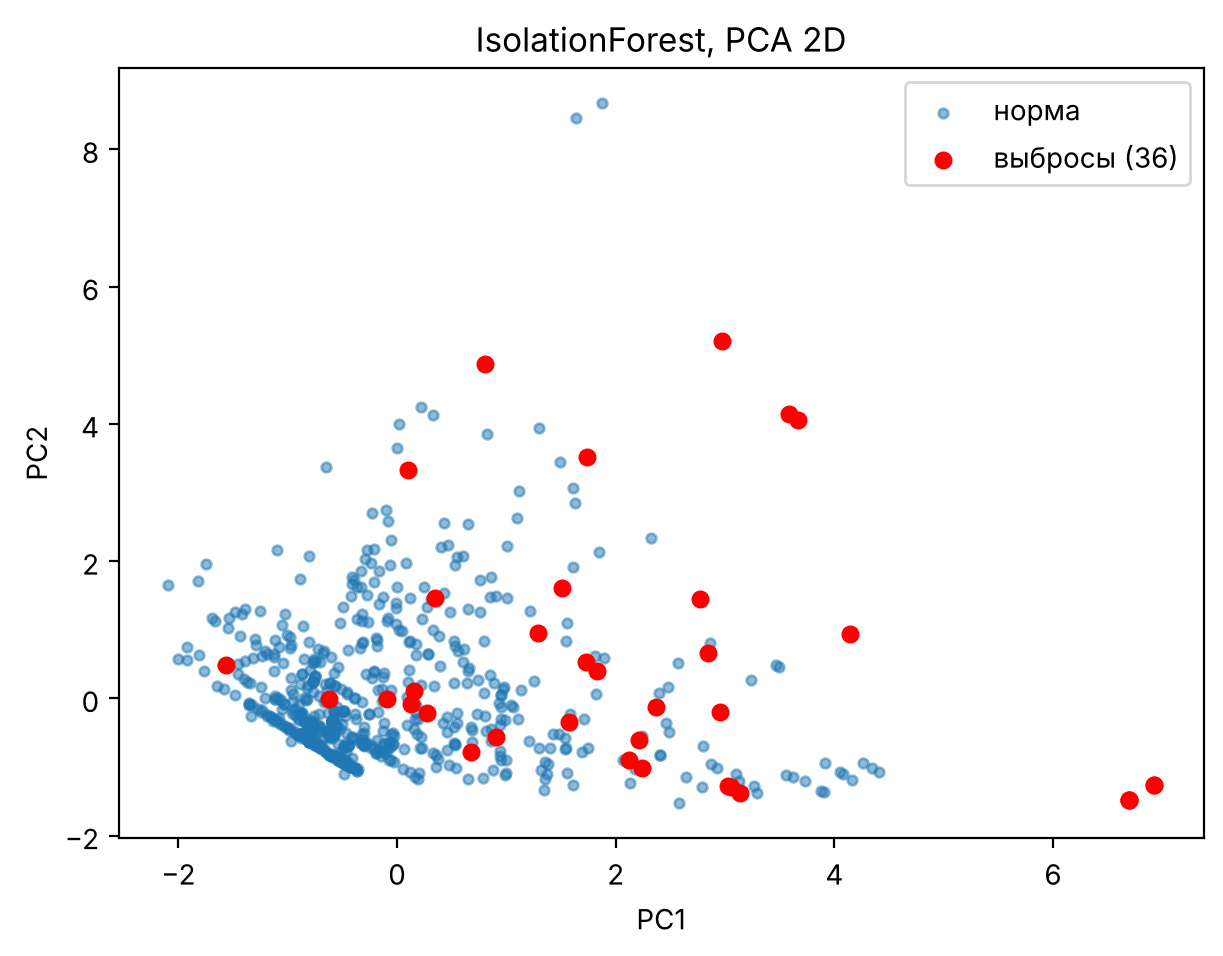

,age,sibsp,parch,fare,pclass
mean,23.5,2.2,1.6,76.8,2.1
max,64.0,8.0,6.0,263.0,3.0


In [6]:
prep = build_pipeline(best_imputer).named_steps["prep"]
Z = prep.fit_transform(X_train)
is_out = IsolationForest(contamination=0.05, random_state=RANDOM_STATE).fit_predict(Z) == -1

P = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z)
plt.figure(figsize=(7, 5))
plt.scatter(*P[~is_out].T, s=12, alpha=0.5, label="норма")
plt.scatter(*P[is_out].T, s=30, c="red", label=f"выбросы ({is_out.sum()})")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.title("IsolationForest, PCA 2D"); plt.show()

X_train[is_out].describe().loc[["mean", "max"]].round(1)  # кто попал в выбросы

`OutlierRemover` (см. `src/transformers.py`) удаляет выбросы только при `fit`, то есть внутри каждого CV-фолда только из его train-части. На валидации и тесте строки не удаляются.

In [7]:
results["+ outlier removal"] = cv_auc(build_pipeline(best_imputer, outliers=OutlierRemover()), X_train, y_train)
pd.DataFrame(results, index=["mean", "std"]).T.round(4)

,mean,std
impute: Simple (median),0.8532,0.0218
impute: KNN (k=5),0.8527,0.0239
impute: Iterative,0.8542,0.0217
+ outlier removal,0.8515,0.0189


## 4. Генерация признаков
Датасет состоит из одной таблицы, поэтому Featuretools не нужен. Вручную добавляем `family_size = sibsp + parch + 1` и `fare_per_person = fare / family_size`,
а затем `PolynomialFeatures(degree=2)` по числовым признакам: квадраты и попарные произведения.

In [8]:
gen = build_pipeline(best_imputer, gen_features=True, outliers=OutlierRemover())
results["+ generated features"] = cv_auc(gen, X_train, y_train)
n_features = gen.fit(X_train, y_train).named_steps["prep"].get_feature_names_out().size
print("признаков после генерации:", n_features)
pd.DataFrame(results, index=["mean", "std"]).T.round(4)

признаков после генерации: 35


,mean,std
impute: Simple (median),0.8532,0.0218
impute: KNN (k=5),0.8527,0.0239
impute: Iterative,0.8542,0.0217
+ outlier removal,0.8515,0.0189
+ generated features,0.8393,0.0356


## 5. Отбор признаков
- **Фильтр — Mutual Information:** оценивает каждый признак отдельно по тому, сколько информации о `y` он несёт. Оставляем top-k.
- **Встроенный — Lasso (L1):** L1-регуляризация зануляет веса бесполезных признаков. Для классификации используем логистическую регрессию с L1 (`l1_ratio=1`).

In [9]:
selectors = {
    "MI (top-10)": SelectKBest(mutual_info_classif, k=10),
    "Lasso (L1)": SelectFromModel(LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1)),
}
for name, sel in selectors.items():
    pipe = build_pipeline(best_imputer, gen_features=True, outliers=OutlierRemover(), select=sel)
    results[f"+ select: {name}"] = cv_auc(pipe, X_train, y_train)
    names = pipe.fit(X_train, y_train).named_steps["prep"].get_feature_names_out()
    print(f"{name}: {pipe.named_steps['select'].get_support().sum()} признаков ->",
          list(names[pipe.named_steps["select"].get_support()]))
pd.DataFrame(results, index=["mean", "std"]).T.round(4)

MI (top-10): 10 признаков -> ['num__fare', 'num__fare_per_person', 'num__sibsp fare_per_person', 'num__parch fare', 'num__parch fare_per_person', 'num__fare^2', 'num__fare fare_per_person', 'num__fare_per_person^2', 'cat__sex_female', 'cat__sex_male']


Lasso (L1): 13 признаков -> ['num__age', 'num__sibsp', 'num__fare', 'num__age sibsp', 'num__age parch', 'num__age fare', 'num__age fare_per_person', 'num__sibsp parch', 'cat__pclass_1', 'cat__pclass_3', 'cat__sex_female', 'cat__sex_male', 'cat__embarked_S']


,mean,std
impute: Simple (median),0.8532,0.0218
impute: KNN (k=5),0.8527,0.0239
impute: Iterative,0.8542,0.0217
+ outlier removal,0.8515,0.0189
+ generated features,0.8393,0.0356
+ select: MI (top-10),0.8242,0.0316
+ select: Lasso (L1),0.8487,0.0284


## 6. Финальная модель
Итоговый пайплайн: генерация → предобработка + импутация → удаление выбросов → отбор → модель.
GridSearchCV сам выбирает метод отбора (MI / Lasso / без отбора), включать ли удаление выбросов и какой взять `C`. Затем модель один раз оцениваем на отложенном test.

In [10]:
final = build_pipeline(best_imputer, gen_features=True)
param_grid = {
    "outliers": ["passthrough", OutlierRemover()],
    "select": ["passthrough", *selectors.values()],
    "model__C": [0.1, 1, 10],
}
gs = grid_search(final, param_grid, X_train, y_train)
test_metrics = evaluate(gs.best_estimator_, X_test, y_test)
test_metrics

best params: {'model__C': 0.1, 'outliers': 'passthrough', 'select': SelectFromModel(estimator=LogisticRegression(C=0.1, l1_ratio=1,
                                             solver='liblinear'))}
best CV ROC-AUC: 0.8590


{'accuracy': 0.7988826815642458, 'roc_auc': 0.863768115942029}

In [11]:
save_model(gs.best_estimator_, "lab2_final.joblib")
summary = pd.DataFrame(results, index=["cv_mean", "cv_std"]).T.round(4)
summary.loc["FINAL (GridSearch) CV"] = [round(gs.best_score_, 4), None]
summary.loc["FINAL test ROC-AUC"] = [round(test_metrics["roc_auc"], 4), None]
summary

saved /home/claude/adm-labs/models/lab2_final.joblib


,cv_mean,cv_std
impute: Simple (median),0.8532,0.0218
impute: KNN (k=5),0.8527,0.0239
impute: Iterative,0.8542,0.0217
+ outlier removal,0.8515,0.0189
+ generated features,0.8393,0.0356
+ select: MI (top-10),0.8242,0.0316
+ select: Lasso (L1),0.8487,0.0284
FINAL (GridSearch) CV,0.8590,NaN
FINAL test ROC-AUC,0.8638,NaN
